# Congestion management examples: two markets on one network (joint seams workshop, August 18, 2026)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/pdockery/wscc9-illustrative-model/blob/main/workshop2_congestion_management.ipynb)

This notebook reproduces the two congestion management examples, in which two market engines clear independently on the WSCC 9-bus network and one line inside Market A binds. Its tables compare Market A's production cost before and after it accommodates Market B's flow on that line, at Market B's realized flow and at a forecast that overstates it, and the cost of the phantom congestion that the over-forecast adds. The slide checks are in `tests/test_slides_workshop2.py` and run with `python -m pytest tests -q -m slides`.

It follows the deck *Seams Workshop: Congestion Management Examples*, presented at the joint CAISO and SPP market seams workshop of August 18, 2026 (`caiso_spp_workshop_aug2026`). The excerpt is `sources/workshops/2026-08-18_congestion_management_examples.pdf`, and its page $n$ is page $90+n$ of the posted deck. A slide number below is the excerpt's page.

The code runs on the modules in `lib/`. `wscc9_model` and `ieee9_network` build the case, `seams_engine` clears each market, `footprints` holds the market partition, `revenue_allocation` settles Market A's first clear, and `seam_views`, `wscc9_figures` and `nodal_plot` draw the figures.

In [1]:
#@title ▶ Run me first: Colab setup (installs packages, fetches the library)
# On Google Colab this installs the three packages Colab lacks and fetches the 14
# library modules into lib/. Run locally, it walks up from the working directory to
# the folder that holds lib/seams_engine.py and puts that lib/ on sys.path.
import pathlib
import subprocess
import sys

LIB_MODULES = (
    "atc", "bilateral", "etag", "footprints", "ieee9_network", "intertie",
    "lab_types", "nodal_plot", "revenue_allocation", "risk", "seam_views",
    "seams_engine", "wscc9_figures", "wscc9_model",
)

if "google.colab" in sys.modules:
    subprocess.run("pip install -q pypsa pandapower pycirclize", shell=True, check=True)
    _base = "https://raw.githubusercontent.com/pdockery/wscc9-illustrative-model/main/lib"
    _lib = pathlib.Path.cwd() / "lib"
    _lib.mkdir(exist_ok=True)
    for _m in LIB_MODULES:
        subprocess.run(f"wget -q {_base}/{_m}.py -O {_lib / _m}.py", shell=True, check=True)
else:
    _root = pathlib.Path.cwd()
    while not (_root / "lib" / "seams_engine.py").exists():
        if _root == _root.parent:
            raise FileNotFoundError(
                f"no lib/seams_engine.py in {pathlib.Path.cwd()} or any folder above it")
        _root = _root.parent
    _lib = _root / "lib"
if str(_lib) not in sys.path:
    sys.path.insert(0, str(_lib))
print("Colab setup complete." if "google.colab" in sys.modules
      else "Local run: modules from the repository's lib/")

Local run: modules from the repository's lib/


In [2]:
import logging
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Patch

import footprints
import seam_views
from nodal_plot import plot_combined_letter, plot_network_topology
from revenue_allocation import capacity_value_by_line, settlement_by_bus
from seams_engine import compute_ptdf, solve_engine_dispatch, susceptance_widths
from wscc9_model import BUS_COLORS, CENTER_BUS, COORDS, RING_ORDER, build_network, make_engine

warnings.filterwarnings("ignore")
logging.getLogger("pypsa").setLevel(logging.ERROR)
logging.getLogger("ieee9_network").setLevel(logging.WARNING)
pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 80)

# Every seam_views frame draws inline with no suptitle or panel title and writes no file.
seam_views.configure(strip_inline=True, save_enabled=False)

## Formulation

Each market is a clearing engine that dispatches its own resources against its own load on the shared 9-bus network. It computes its own flow contribution on every line and enforces a limit only on the lines it activates. In the protocol for coordinated congestion relief between regions, "each regional system operator need monitor only its own constraints, but it does need to determine the flows in the network" (`cadwalader1999coordinating`, p. 23). Each engine here meets the first condition, because it enforces only its own activated lines. For the second, it carries the input $\widehat F^{M'}$ of (1), its estimate of the other market's flow, which Example 1 sets to zero and Example 2 sets to a forecast.

**Nomenclature.** Sets are script capitals, an element is the matching lower-case letter, and upper case names a market engine.

| Symbol | Code | Definition |
|---|---|---|
| $\mathcal N$, $n$ | `pt.buses` | the set of buses; $n\in\mathcal N$ |
| $\mathcal M$, $m$ | `pt.lines` | the network line set, every line of the shared network; $m\in\mathcal M$ |
| $SF_{n,m}$ | `pt.ptdf[m, n]` | shift factor of bus $n$ on line $m$, with bus 1 the reference bus; the array is indexed line first |
| $\bar F_m$ | `pt.s_nom` | rating of line $m$ |
| $\mathcal E$, $M$, $M'$ | `make_engine` | the set of market engines, $\mathcal E=\{A,B\}$; $M'$ is the market other than $M$ |
| $\mathcal R^M$, $i$ | `eng.gens` | market $M$'s resources |
| $c_i$, $\bar g_i$ | `eng.gens[i]["cost"]`, `eng.gens[i]["p_nom"]` | resource $i$'s offer price and capacity |
| $g^M_i$, $g^M_{(n)}$ | `res.dispatch`, `res.gen_by_bus` | dispatch of resource $i$; market $M$'s dispatch summed at bus $n$ |
| $d^M_n$ | `eng.loads` | market $M$'s load at bus $n$ |
| $\mathcal M^M_{\mathrm{mon}}$ | `MONITORED_LINES` | market $M$'s monitored lines, the subset of $\mathcal M$ it models and watches |
| $\mathcal M^M_{\mathrm{act}}$ | `ACTIVATED_LINES`, `eng.activated_lines` | market $M$'s activated set, the monitored lines whose limits it enforces; $\mathcal M^M_{\mathrm{act}}\subseteq\mathcal M^M_{\mathrm{mon}}$ |
| $F^M_m$ | `res.flow_own` | market $M$'s flow contribution on line $m$ |
| $\widehat F^{M'}_m$ | `flow_offsets=` | the flow of market $M'$ on line $m$ that market $M$ carries as a fixed input |
| $F^s_m$ | `physical_flows` (`F_phys`), `superposed` | the superposed flow, the flow line $m$ carries; `superposed` is its unrounded form |
| $\lambda^M$, $\lambda^M_n$ | `res.energy_price`, `res.lmp` | market $M$'s energy price and its nodal LMP at bus $n$ |
| $\mu^M_m$ | `res.line_dual` | market $M$'s signed dual of line $m$'s limit; printed values show $\lvert\mu^M_m\rvert$ |
| $\Delta g_i$ | `price_walk`, `line_walk`, `accommodation_ledger` | the redispatch of resource $i$, in a production-cost walk or between two clears of one market |
| $R^M$ | `settlement_by_bus`, `capacity_value_by_line` | market $M$'s congestion rent, the settlement total and the line total of (6) |
| $C^M$ | `res.total_cost`, `cost_table` | market $M$'s production cost |

**The program.** Market $M$ clears

$$\min_{0\le g^M_i\le\bar g_i}\ C^M=\sum_{i\in\mathcal R^M}c_i\,g^M_i\quad\text{s.t.}\quad\sum_{i\in\mathcal R^M}g^M_i=\sum_{n\in\mathcal N}d^M_n\ \ [\lambda^M],\qquad -\bar F_m\le F^M_m+\widehat F^{M'}_m\le\bar F_m\ \ [\mu^M_m],\ \ m\in\mathcal M^M_{\mathrm{act}}. \qquad (1)$$

*In words.* Market $M$ minimizes its production cost $C^M$, the offer price $c_i$ times the dispatch $g^M_i$ summed over its resources $\mathcal R^M$, with each dispatch within its capacity $\bar g_i$, subject to two constraint families: its dispatch equals the load it serves (dual $\lambda^M$, its energy price); and on each activated line $m\in\mathcal M^M_{\mathrm{act}}$, its own flow contribution $F^M_m$ plus the flow of the other market it carries as an input, $\widehat F^{M'}_m$, stays within the rating $\bar F_m$ (dual $\mu^M_m$, that line's signed shadow price).

The examples set the input $\widehat F^{M'}$ three ways. Example 1 clears with $\widehat F^{M'}=0$. Example 2 sets it to the flow of a forecast of the other market's book. The redispatch sets it to the other market's realized flow. The engine also carries load shedding at the shed price, and no clear in this notebook sheds.

**The flow contribution.**

$$F^M_m=\sum_{n\in\mathcal N}SF_{n,m}\big(g^M_{(n)}-d^M_n\big)\qquad(m\in\mathcal M). \qquad (2)$$

*In words.* Market $M$'s flow contribution $F^M_m$ on line $m$ is each bus's shift factor $SF_{n,m}$ on that line times market $M$'s net injection there, its dispatch at the bus $g^M_{(n)}$ less its load $d^M_n$, summed over every bus $n\in\mathcal N$. Note that the other market's buses carry no injection in $F^M_m$, although their shift factors need not be zero. On line 6-7, Market B's buses 5 and 9 have shift factors of $+0.135$ and $-0.125$.

$F^M_m$ is the Market Flow of the PJM and MISO congestion management design: "When a Market-Based Operating Entity’s dispatch creates flows on a Coordinated Flowgate, those flows can be quantified and considered the Market Flow" (`pjm_miso_cm2003`, p. 19).

**The superposed flow.** Flows are linear in the injections, so the two contributions add.

$$F^s_m=\sum_{M\in\mathcal E}F^M_m\qquad(m\in\mathcal M). \qquad (3)$$

*In words.* The superposed flow $F^s_m$ on line $m$ is the sum of every market's flow contribution $F^M_m$ over the engine set $\mathcal E$.

**What each market enforces, and what the line carries.**

$$\big|F^M_m+\widehat F^{M'}_m\big|\le\bar F_m\ \ \text{for each }M\in\mathcal E\quad\nRightarrow\quad\big|F^s_m\big|\le\bar F_m. \qquad (4)$$

*In words.* Each market $M$ holding its own flow contribution plus its input, $\lvert F^M_m+\widehat F^{M'}_m\rvert$, within the rating $\bar F_m$ does not imply that the superposed flow $\lvert F^s_m\rvert$ is within the same rating.

On a line that market $M$ enforces, $\lvert F^M_m+\widehat F^{M'}_m\rvert\le\bar F_m$ implies $\lvert F^s_m\rvert\le\bar F_m$ when the input $\widehat F^{M'}_m$ equals the other market's realized contribution $F^{M'}_m$.

**The nodal price.**

$$\lambda^M_n=\lambda^M+\sum_{m\in\mathcal M^M_{\mathrm{act}}}SF_{n,m}\,\mu^M_m. \qquad (5)$$

*In words.* Market $M$'s nodal LMP $\lambda^M_n$ at bus $n$ is its energy price $\lambda^M$ plus, summed over its activated set, each line's shift factor $SF_{n,m}$ from that bus times the line's signed dual $\mu^M_m$. Note that the energy price is the price at the reference bus, bus 1, whose shift factors are zero.

The EDAM technical description writes the LMP in a form that differs from (5) in four ways (`caiso_edam_techdesc`, p. 26). It divides the energy price by a loss penalty factor, and (5) is lossless, the reading with that factor at 1. It carries an energy price $\lambda_j$ for each balancing authority area $j$, and (5) carries one energy price $\lambda^M$ per market, the dual of the single balance of (1) that `solve_engine_dispatch` solves. It adds the imbalance-reserve deployment duals and a greenhouse-gas term, and (5) has neither. It writes the dual with a minus sign, so its $\mu_{m,t}$ is the negative of the signed $\mu^M_m$ of (5).

A price in (5) is also a production-cost change, which slides 7 and 8 compute. Line $m$ binds, resources $i$ and $j$ are interior, and $SF_{(i),m}$ is the shift factor of resource $i$'s bus.

1. One more MW of load at bus $n$ moves the pair by $\Delta g_i+\Delta g_j=1$ and $SF_{(i),m}\Delta g_i+SF_{(j),m}\Delta g_j=SF_{n,m}$, so line $m$ stays at its rating, and the LMP is the pair's cost, $\lambda^M_n=c_i\Delta g_i+c_j\Delta g_j$.
2. One MW off line $m$ moves the pair by $\Delta g_i+\Delta g_j=0$ and $SF_{(i),m}\Delta g_i+SF_{(j),m}\Delta g_j=\operatorname{sgn}\mu^M_m$, so load is unchanged and the line's absolute flow falls by 1 MW, and the absolute dual is the pair's cost, $\lvert\mu^M_m\rvert=c_i\Delta g_i+c_j\Delta g_j$.

**The congestion rent.**

$$R^M=\sum_{m\in\mathcal M^M_{\mathrm{act}}}\lvert\mu^M_m\rvert\,\lvert F^M_m\rvert=\sum_{n\in\mathcal N}\lambda^M_n d^M_n-\sum_{n\in\mathcal N}\lambda^M_n g^M_{(n)}. \qquad (6)$$

*In words.* Market $M$'s congestion rent $R^M$ is the absolute dual $\lvert\mu^M_m\rvert$ times the absolute own flow $\lvert F^M_m\rvert$, summed over its activated lines. It equals what market $M$'s load pays, $\sum_n\lambda^M_n d^M_n$, less what its generation is paid, $\sum_n\lambda^M_n g^M_{(n)}$.

**The cost of an input.**

$$C^A\big(\widehat F^{B}\big)-C^A(0)=\lvert\mu^A_m\rvert\,\widehat F^{B}_m. \qquad (7)$$

*In words.* The change in Market A's production cost $C^A$ when it carries Market B's flow $\widehat F^{B}$ as an input, against its clear with none, is the absolute dual $\lvert\mu^A_m\rvert$ of its binding line $m$ times Market B's flow $\widehat F^{B}_m$ on that line.

The identity holds while line $m$ is Market A's only binding line, the input shares the sign of Market A's flow on it, and the same two resources stay interior, so that $\lvert\mu^A_m\rvert$ does not change. Every Market A clear in this notebook meets the three conditions, and each clear prints its $\lvert\mu^A_m\rvert$.

## The case (slides 3 and 4)

The network is pandapower's `case9`, the WSCC 3-machine, 9-bus system, as slide 3 states. It has 3 generators, 3 loads and 9 lines. Market A holds buses 2, 8, 7, 6 and 3, with the \$20/MWh unit at bus 3, the \$35/MWh unit at bus 2 and the load at bus 7. Market B holds buses 1, 9, 4 and 5, with the \$50/MWh unit at bus 1 and the loads at buses 5 and 9. Two intertie lines cross the partition. Market A monitors and activates `line_2` (5-6), and Market B monitors and activates `line_7` (8-9). Every other line is monitored and activated by the market that holds both its ends.

Line 6-7 (`line_4`) is rated 40 MW, against case9's 150 MW, and it binds in Market A's clears in both examples. The linear offers and the bus-3 unit's 170 MW capacity are this repository's case settings, where case9 has polynomial costs and 270 MW. The bus-1 unit is raised from the library's default 250 MW, case9's value, to 300 MW, and its outlet `line_0` (1-4) is raised from 250 MW to 300 MW with it.

Slide 4 shows the configured loads. The examples clear at four drawn loads: the realized loads at buses 7 and 9, Market A's forecast of the bus-9 load and Market B's forecast of the bus-7 load. Each comment states its value's distribution and seed, and for Market A's forecast the rule that selects the draw. Each value is entered at full precision.

**Edit below:** the footprints, the monitored and activated lines, the line ratings, the fleet, the configured loads, the four drawn loads and the shed price.

In [3]:
# -- EDIT -- the case both examples clear ------------------------------------
MARKETS = {                                      # market footprints, buses by name
    "Market A": ["2", "8", "7", "6", "3"],
    "Market B": ["1", "9", "4", "5"],
}
MARKET_COLORS = {"Market A": "#993AFF", "Market B": "#2471A3"}   # figure colors
MONITORED_LINES = {                              # lines each market models and watches
    "Market A": ["line_2", "line_3", "line_4", "line_5", "line_6"],   # line_2: 5-6
    "Market B": ["line_0", "line_1", "line_7", "line_8"],             # line_7: 8-9
}
ACTIVATED_LINES = {                              # monitored lines whose limits it enforces
    "Market A": ["line_2", "line_3", "line_4", "line_5", "line_6"],
    "Market B": ["line_0", "line_1", "line_7", "line_8"],
}
LINE_RATINGS = {"line_4": 40.0, "line_0": 300.0}   # MW, overrides of the default ratings
GEN_FLEET = {                                    # unit: bus, offer $/MWh, capacity MW
    "gen_1": {"bus": "3", "cost": 20.0, "p_nom": 170.0},
    "gen_0": {"bus": "2", "cost": 35.0, "p_nom": 300.0},
    "gen_slack_0": {"bus": "1", "cost": 50.0, "p_nom": 300.0},    # library default 250 MW
}
CONFIGURED_LOADS = {"5": 90.0, "7": 100.0, "9": 125.0}   # MW, the case as configured
# Realized loads: N(100, 10) then N(125, 30), two draws of one default_rng(59).
LOAD_7 = 89.9300428769044                # MW, realized bus 7 load
LOAD_9 = 173.06985787642174              # MW, realized bus 9 load
# A's forecast of bus 9: the realized load plus N(0, 15). default_rng(66) draws
# (bus 7, bus 9) pairs, the bus 7 draw at sd 0. The 4th pair is the first whose
# Market B flow on line 6-7 exceeds Market B's realized flow by more than 2 MW.
LOAD_9_FORECAST_BY_A = 189.86410191559406   # MW, A's forecast of bus 9
# B's forecast of bus 7: the realized load plus N(0, 5), default_rng(160)'s first draw.
LOAD_7_FORECAST_BY_B = 83.05506264517608    # MW, B's forecast of bus 7
SHED_PRICE = 150.0                       # $/MWh, value of shed load
SLACK_BUS = "1"                          # reference bus of the shift factors
STUDY_LINE = "line_4"                    # line 6-7, Market A's binding line

In [4]:
net = build_network(LINE_RATINGS)
pt = compute_ptdf(net, slack_bus=SLACK_BUS)
fp = footprints.make(pt, MARKETS, MARKET_COLORS, monitored=MONITORED_LINES,
                     tie_label="intertie")
seam_views.configure(fp=fp, gen_fleet=GEN_FLEET, loads=CONFIGURED_LOADS)
for _mkt in MARKETS:
    _extra = set(ACTIVATED_LINES[_mkt]) - set(MONITORED_LINES[_mkt])
    assert not _extra, f"{_mkt}: activated but not monitored: {sorted(_extra)}"

_units = sorted(GEN_FLEET.items(), key=lambda kv: kv[1]["cost"])
print("fleet: " + ", ".join(f"{g} bus {s['bus']} ${s['cost']:.0f}/MWh x {s['p_nom']:.0f} MW"
                            for g, s in _units))
print("configured loads: " + ", ".join(f"bus {b} {v:.0f} MW"
                                       for b, v in CONFIGURED_LOADS.items()))
print(f"cleared loads: bus 5 {CONFIGURED_LOADS['5']:.2f} MW, bus 7 {LOAD_7:.2f} MW, "
      f"bus 9 {LOAD_9:.2f} MW")
footprints.line_status_table(fp, pt, MONITORED_LINES, ACTIVATED_LINES).assign(
    rating_MW=np.round(pt.s_nom, 1))

fleet: gen_1 bus 3 $20/MWh x 170 MW, gen_0 bus 2 $35/MWh x 300 MW, gen_slack_0 bus 1 $50/MWh x 300 MW

configured loads: bus 5 90 MW, bus 7 100 MW, bus 9 125 MW

cleared loads: bus 5 90.00 MW, bus 7 89.93 MW, bus 9 173.07 MW

,ends,location,Market A,Market B,rating_MW
line,,,,,
line_0,1-4,internal Market B,--,enforces,300.0
line_1,4-5,internal Market B,--,enforces,250.0
line_2,5-6,intertie,enforces,--,150.0
line_3,3-6,internal Market A,enforces,--,300.0
line_4,6-7,internal Market A,enforces,--,40.0
line_5,7-8,internal Market A,enforces,--,250.0
line_6,8-2,internal Market A,enforces,--,250.0
line_7,8-9,intertie,--,enforces,250.0
line_8,9-4,internal Market B,--,enforces,250.0


## Notebook-local helpers

`engine_a` and `engine_b` build each market's engine at a given load, and `clear` solves one and stops if it sheds load. `offsets_on` reads the other market's flow on an engine's activated lines, the input $\widehat F^{M'}_m$ of (1). `superposed` sums the flow contributions for (3), unrounded, where `seams_engine.physical_flows` rounds to 0.1 MW. `line_walk` and `line_walk_text` compute the second walk under (5). `market_block` prints one clear. `cost_table` sets Market A's clears side by side. `accommodation_ledger` states the cost of one input against (7), and `phantom_ledger` states the cost of two inputs and their difference against (7). `ledger_text` prints a table at each unit's precision. `footprint_map` and `config_figure` draw slides 3 and 4. `run_chain` is the sandbox of the last section.

In [5]:
def engine_a(load_7):
    """Market A's engine with its bus 7 load at ``load_7`` MW."""
    return make_engine("Market A", MARKETS["Market A"], gen_fleet=GEN_FLEET,
                       loads={**CONFIGURED_LOADS, "7": float(load_7)},
                       activated=ACTIVATED_LINES["Market A"])


def engine_b(load_9):
    """Market B's engine with its bus 9 load at ``load_9`` MW."""
    return make_engine("Market B", MARKETS["Market B"], gen_fleet=GEN_FLEET,
                       loads={**CONFIGURED_LOADS, "9": float(load_9)},
                       activated=ACTIVATED_LINES["Market B"])


def clear(eng, offsets=None):
    """Clear (1) for ``eng`` with the input ``offsets`` ({line: MW}) on its activated lines.

    Stops if the clear sheds load, because (7) assumes none.
    """
    res = solve_engine_dispatch(pt, eng, flow_offsets=offsets, shed_price=SHED_PRICE)
    shed = sum(res.shed_by_bus.values())
    assert shed < 1e-6, f"{eng.name} sheds {shed:.3f} MW"
    return res


def offsets_on(res_other, eng):
    """The other market's flow contribution on ``eng``'s activated lines, MW."""
    return {m: float(res_other.flow_own[m]) for m in eng.activated_lines}


def superposed(*results):
    """The superposed flow (3), {line: MW}, unrounded; ``physical_flows`` rounds it to 0.1 MW."""
    return {m: float(sum(r.flow_own[m] for r in results)) for m in pt.lines}


def line_ends(m):
    """The line's ends as text, such as ``6-7``."""
    return "-".join(pt.line_buses[pt.line_idx[m]])


def units_by_bus(eng):
    """The engine's units in bus order."""
    return sorted(eng.gens, key=lambda g: str(eng.gens[g]["bus"]))


def line_walk(eng, res, line, tol=1e-6):
    """One MW off ``line``, redispatched across the interior units (the walk under (5)).

    Solves sum_i dg_i = 0, SF[line] . dg = sgn(mu_line) and SF[k] . dg = 0 for every
    other binding line k, over the units strictly inside their bounds. Returns one row
    per unit (bus, offer, redispatch, cost change); the cost changes sum to |mu_line|.
    """
    units = [g for g, v in res.dispatch.items()
             if tol < v < float(eng.gens[g]["p_nom"]) - tol]
    binding = [k for k, v in res.line_dual.items() if abs(v) > tol]
    if line not in binding:
        raise ValueError(f"{line} does not bind in {eng.name}'s clear")
    rows, rhs = [[1.0] * len(units)], [0.0]
    for k in binding:
        rows.append([pt.ptdf[pt.line_idx[k], pt.bus_idx[str(eng.gens[g]["bus"])]]
                     for g in units])
        rhs.append(float(np.sign(res.line_dual[k])) if k == line else 0.0)
    dg, *_ = np.linalg.lstsq(np.asarray(rows), np.asarray(rhs), rcond=None)
    return pd.DataFrame([{
        "unit": g, "bus": str(eng.gens[g]["bus"]),
        "offer ($/MWh)": float(eng.gens[g]["cost"]),
        "redispatch (MW)": float(dg[i]),
        "cost change ($/h)": float(eng.gens[g]["cost"]) * float(dg[i]),
    } for i, g in enumerate(units)]).set_index("unit")


def line_walk_text(walk, line, market, mu):
    """The line walk as a block of text, closed by the line's absolute dual."""
    out = [f"{market} -- line {line_ends(line)} ({line}): the cost of one MW off the line", ""]
    for unit, r in walk.iterrows():
        lhs = (f"{unit} at bus {r['bus']}: {r['redispatch (MW)']:+.4f} MW"
               f"  x  ${r['offer ($/MWh)']:,.2f}/MWh")
        out.append(f"  {lhs:<52}=  ${r['cost change ($/h)']:>+9,.2f}/h")
    out.append("  " + "-" * 66)
    out.append(f"  {'change in production cost':<52}=  "
               f"${walk['cost change ($/h)'].sum():>+9,.2f}/h")
    out.append(f"  {market + ' |mu| on ' + line:<52}=  ${abs(mu):>9,.2f}/MWh")
    return "\n".join(out)


def market_block(eng, res, offsets=None):
    """Print one clear: cost, energy price, dispatch, the study line and every LMP."""
    offsets = offsets or {}
    m = STUDY_LINE
    act = "" if m in eng.activated_lines else ", not in the activated set"
    print(f"{eng.name}: production cost ${res.total_cost:,.2f}/h, "
          f"energy price ${res.energy_price:.3f}/MWh")
    print("  dispatch: " + ", ".join(
        f"{g} at bus {eng.gens[g]['bus']} {mw:.2f} MW" for g, mw in res.dispatch.items()))
    print(f"  {m} ({line_ends(m)}): own flow {res.flow_own[m]:+.3f} MW, input "
          f"{offsets.get(m, 0.0):+.3f} MW, rating {pt.s_nom[pt.line_idx[m]]:.0f} MW, "
          f"|mu| {abs(res.line_dual.get(m, 0.0)):.4f} $/MWh{act}")
    print("  LMP ($/MWh): " + ", ".join(f"bus {b} {res.lmp[b]:.3f}" for b in pt.buses))


def cost_table(eng, clears, res_b):
    """Market A's clears side by side: each unit's dispatch, C^A and the study line's flows.

    ``clears`` is a list of (label, result, offsets), where ``offsets`` is the input
    ({line: MW}) the clear carried, or None. The input, Market A's own flow, the
    superposed flow (3) with Market B's clear ``res_b``, the rating and |mu| are those
    of the study line. One row per clear, in MW, $/h and $/MWh.
    """
    m = STUDY_LINE
    rows = {}
    for label, res, offsets in clears:
        rows[label] = {
            **{f"bus {eng.gens[g]['bus']} unit (MW)": res.dispatch[g] for g in units_by_bus(eng)},
            "production cost ($/h)": res.total_cost,
            "input (MW)": (offsets or {}).get(m, 0.0),
            "own flow (MW)": res.flow_own[m],
            "superposed (MW)": superposed(res, res_b)[m],
            "rating (MW)": float(pt.s_nom[pt.line_idx[m]]),
            "|mu| ($/MWh)": abs(res.line_dual.get(m, 0.0)),
        }
    return pd.DataFrame.from_dict(rows, orient="index")


def accommodation_ledger(eng, res_0, res_1, flow_in):
    """The cost of one input as a ledger: Market A's redispatch between two clears, against (7).

    ``res_0`` is the clear with no input and ``res_1`` the clear with the input ``flow_in``
    (MW) on the study line. One row per unit, its redispatch times its offer, then their
    sum, the (7) row ``flow_in`` times the |mu| of ``res_0``, and the residual.
    """
    mu = abs(res_0.line_dual.get(STUDY_LINE, 0.0))
    rows = {}
    for g in units_by_bus(eng):
        dg, offer = res_1.dispatch[g] - res_0.dispatch[g], float(eng.gens[g]["cost"])
        rows[f"{g} at bus {eng.gens[g]['bus']}: redispatch x offer"] = (dg, offer, dg * offer)
    change = sum(v[2] for v in rows.values())
    rows["change in production cost, the sum"] = (np.nan, np.nan, change)
    rows["(7): input x |mu|"] = (flow_in, mu, flow_in * mu)
    rows["residual, the sum less (7)"] = (np.nan, np.nan, change - flow_in * mu)
    return pd.DataFrame.from_dict(rows, orient="index",
                                  columns=["quantity (MW)", "price ($/MWh)", "cost ($/h)"])


def phantom_ledger(res_0, res_r, res_f, res_b, flow_hat):
    """The cost of phantom congestion as a ledger: (7) at Market B's realized flow and at the forecast.

    ``res_0``, ``res_r`` and ``res_f`` are Market A's clears with no input, with Market B's
    realized flow (that of ``res_b``) and with the forecast ``flow_hat`` (MW) on the study
    line. Each cost row sets the clears' cost change beside (7) at the |mu| of ``res_0``,
    with the residual. The flow rows give the superposed flow (3) of ``res_f`` and
    ``res_b``, the rating and the capacity the superposed flow leaves unused.
    """
    m = STUDY_LINE
    mu = abs(res_0.line_dual.get(m, 0.0))
    flow_b = res_b.flow_own[m]
    costs = {
        "accommodating Market B's realized flow: C^A(F^B) - C^A(0)":
            (flow_b, res_r.total_cost - res_0.total_cost),
        "accommodating the forecast: C^A(forecast) - C^A(0)":
            (flow_hat, res_f.total_cost - res_0.total_cost),
        "phantom congestion: C^A(forecast) - C^A(F^B)":
            (flow_hat - flow_b, res_f.total_cost - res_r.total_cost),
    }
    rows = {k: (mw, mu, dc, mu * mw, dc - mu * mw) for k, (mw, dc) in costs.items()}
    flow_s = superposed(res_f, res_b)[m]
    rating = float(pt.s_nom[pt.line_idx[m]])
    rows["superposed flow, forecast clear with Market B's clear"] = (flow_s, *[np.nan] * 4)
    rows["rating"] = (rating, *[np.nan] * 4)
    rows["unused capacity, rating less superposed flow"] = (rating - abs(flow_s), *[np.nan] * 4)
    return pd.DataFrame.from_dict(rows, orient="index", columns=[
        f"line {line_ends(m)} (MW)", "|mu| ($/MWh)", "from the clears ($/h)",
        "(7): |mu| x MW ($/h)", "residual ($/h)"])


def ledger_text(table, title):
    """``table`` under ``title`` as text, each column at its unit's precision.

    A column in MW prints to 0.001 MW, in $/MWh to $0.0001/MWh and in $/h to $0.01/h. An
    empty cell prints blank, and a value that rounds to zero prints without a sign.
    """
    digits = {"(MW)": 3, "($/MWh)": 4, "($/h)": 2}

    def fmt(nd):
        return lambda v: "" if pd.isna(v) else f"{round(float(v), nd) + 0.0:,.{nd}f}"

    formatters = {c: fmt(next(nd for unit, nd in digits.items() if c.endswith(unit)))
                  for c in table.columns}
    return f"{title}\n{table.to_string(formatters=formatters, na_rep='')}"


def footprint_map():
    """Slide 3: the two footprints, lines colored by the market that monitors them."""
    fig, ax = plot_network_topology(
        net, supply_by_bus={}, demand_by_bus={},
        bus_colors={b: MARKET_COLORS[fp.fp_of(b)] for b in pt.buses}, bus_coords=COORDS,
        line_flows={m: 0.0 for m in pt.lines}, line_widths=susceptance_widths(pt),
        line_colors=fp.line_colors(pt), title="")
    ax.legend(handles=[Patch(color=c, label=n) for n, c in MARKET_COLORS.items()],
              loc="lower left", fontsize=9, framealpha=0.9)
    return fig


def config_figure():
    """Slide 4: the case as configured, every unit at nameplate and no clearing in it."""
    sup = {}
    for gid, spec in GEN_FLEET.items():
        cap = float(spec["p_nom"])
        sup.setdefault(str(spec["bus"]), []).append({
            "unit_id": gid, "price": float(spec["cost"]), "volume": cap,
            "capacity": cap, "accepted_volume": cap})
    dem = {str(b): float(v) for b, v in CONFIGURED_LOADS.items() if v > 0}
    p_ref = max(float(s["cost"]) for s in GEN_FLEET.values())
    fig, (ax, _ring) = plot_combined_letter(
        net, sup, dem, bus_colors=dict(BUS_COLORS),
        bus_lmps={b: p_ref for b in pt.buses}, show_bus_price=False,
        bus_net_mw=None, network_show_lmp=False,
        line_flows={m: 0.0 for m in pt.lines}, line_widths=susceptance_widths(pt),
        line_colors=fp.line_colors(pt), flows=[], lmp_line=False,
        bus_groups={b: fp.fp_of(b) for b in pt.buses}, group_colors=dict(MARKET_COLORS),
        show_group_labels=False, all_buses=pt.buses, sector_order=RING_ORDER,
        bus_coords=COORDS, center_bus=CENTER_BUS, annotate_roles=True, axis_key=True,
        title_left="", title_right="")
    for m, (b0, b1) in zip(pt.lines, pt.line_buses):
        (x0, y0), (x1, y1) = COORDS[b0], COORDS[b1]
        em = m == STUDY_LINE
        ax.text((x0 + x1) / 2, (y0 + y1) / 2, f"{pt.s_nom[pt.line_idx[m]]:.0f} MW",
                fontsize=7.5 if em else 6.5, ha="center", va="center",
                color="#B03A2E" if em else "#5D6D7E", fontweight="bold" if em else "normal",
                bbox=dict(fc="white", ec="#B03A2E" if em else "none", alpha=0.9,
                          pad=1.4 if em else 1), zorder=6)
    return seam_views.strip(fig)


def run_chain(load_7=None, load_9=None, load_9_forecast=None):
    """The sandbox: Market B's clear and Market A's three clears, on the EDIT cell's case.

    Each argument defaults to the EDIT cell's value. Prints the bottom lines of the two
    ledgers, the cost of accommodation and the cost of phantom congestion, each with its
    residual of (7) and the superposed flow on the study line against its rating. Returns
    one row per clear with its cost and the study line's flows.
    """
    load_7 = LOAD_7 if load_7 is None else load_7
    load_9 = LOAD_9 if load_9 is None else load_9
    load_9_forecast = LOAD_9_FORECAST_BY_A if load_9_forecast is None else load_9_forecast
    m = STUDY_LINE
    r_b = clear(engine_b(load_9))
    r_bf = clear(engine_b(load_9_forecast))
    r_a = clear(engine_a(load_7))
    r_ar = clear(engine_a(load_7), offsets_on(r_b, engine_a(load_7)))
    r_af = clear(engine_a(load_7), offsets_on(r_bf, engine_a(load_7)))
    rows = [("Market B", r_b, 0.0, np.nan)]
    rows += [(name, r, inp, r.flow_own[m] + r_b.flow_own[m]) for name, r, inp in (
        ("Market A, no input (Example 1)", r_a, 0.0),
        ("Market A, input = B's realized flow", r_ar, r_b.flow_own[m]),
        ("Market A, input = forecast of B (Example 2)", r_af, r_bf.flow_own[m]))]
    table = pd.DataFrame([{
        "clear": name, "production cost ($/h)": r.total_cost,
        f"own flow {m} (MW)": r.flow_own[m], f"input {m} (MW)": inp,
        f"superposed {m} (MW)": fs, "|mu| ($/MWh)": abs(r.line_dual.get(m, 0.0)),
    } for name, r, inp, fs in rows]).set_index("clear")
    acc = accommodation_ledger(engine_a(load_7), r_a, r_ar, r_b.flow_own[m])["cost ($/h)"]
    ph = phantom_ledger(r_a, r_ar, r_af, r_b, r_bf.flow_own[m])
    phantom = ph.loc["phantom congestion: C^A(forecast) - C^A(F^B)"]
    flow_mw = ph[f"line {line_ends(m)} (MW)"]
    flow_s = flow_mw["superposed flow, forecast clear with Market B's clear"]
    rating = float(pt.s_nom[pt.line_idx[m]])
    print(f"{m} ({line_ends(m)}) rating {rating:.0f} MW; "
          f"Market B's realized flow on it {r_b.flow_own[m]:+.3f} MW, "
          f"the forecast {r_bf.flow_own[m]:+.3f} MW")
    print(f"cost of accommodation: {acc['change in production cost, the sum']:+,.2f} $/h; "
          f"(7) |mu| x F^B {acc['(7): input x |mu|']:+,.2f} $/h; residual "
          f"{round(acc['residual, the sum less (7)'], 2) + 0.0:,.2f} $/h; superposed flow "
          f"{superposed(r_a, r_b)[m]:.3f} MW with no input and {superposed(r_ar, r_b)[m]:.3f} MW "
          f"after, against {rating:.0f} MW")
    print(f"cost of phantom congestion: {phantom['from the clears ($/h)']:+,.2f} $/h; "
          f"(7) |mu| x (forecast - F^B) {phantom['(7): |mu| x MW ($/h)']:+,.2f} $/h; residual "
          f"{round(phantom['residual ($/h)'], 2) + 0.0:,.2f} $/h; superposed flow "
          f"{flow_s:.3f} MW on the forecast against {rating:.0f} MW, unused "
          f"{flow_mw['unused capacity, rating less superposed flow']:.3f} MW")
    return table.round(3)

### Slide 3: the two footprints

Buses take their market's color. A line takes the color of the one market that monitors it, so the intertie `line_2` (5-6) draws in Market A's purple and `line_7` (8-9) in Market B's blue. Line width rises linearly with the line's susceptance, from the narrowest line to the widest. The figure keeps its Market A and Market B legend, as the slide does.

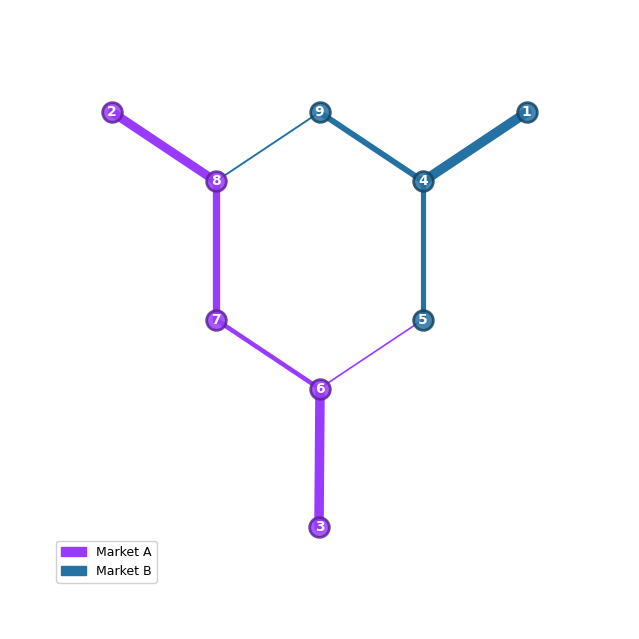

In [6]:
footprint_map()
plt.show()

### Slide 4: the case as configured

This figure carries only what is fixed about the case, and nothing in it is a clearing. Each line is labelled with its rating, and line 6-7's 40 MW is boxed in red. On the ring, each unit is its full nameplate capacity at its offer price, drawn solid. Each load is drawn at the height of the highest offer price, \$50/MWh, so supply and demand share one price axis. There are no chords, because nothing is scheduled.

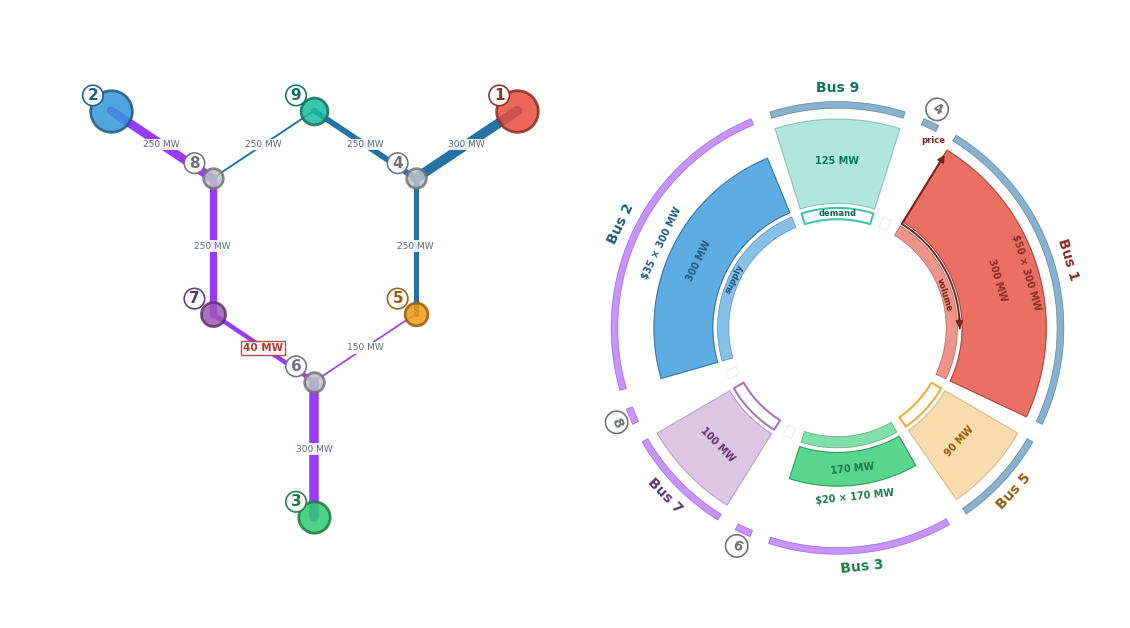

In [7]:
config_figure()
plt.show()

## Example 1: no forecast of the neighbor's flow contribution (slides 5 to 11)

Each market clears (1) with $\widehat F^{M'}=0$. Market A has a binding line, line 6-7, and finds its least-cost dispatch within the limit. Market B has no binding line, and line 6-7 is not in its monitored set $\mathcal M^B_{\mathrm{mon}}$. The superposed flow overloads line 6-7, and Market A then redispatches to bring it back within its rating.

### Slide 6: Market A clears

Market A clears (1) at the realized bus-7 load. Line 6-7 binds at its 40 MW rating. The \$35/MWh unit at bus 2 and the \$20/MWh unit at bus 3 are both interior, and the bus-7 LMP of \$37.1/MWh exceeds both their offers. One more MW at bus 7 with line 6-7 held at its rating raises the bus-2 unit by more than 1 MW and lowers the bus-3 unit, as slide 7 computes. The ring also prices Market B's buses, in gray, at Market A's own LMPs from (5). Market A's production cost is \$2,534.65/h.

Line 6-7 binds at 40 MW with $\lvert\mu^A_m\rvert=\$20.10$/MWh, and Market A's congestion rent by (6) is $R^A=\$804.1$/h. The cell below prints Market A's settlement by bus and its rent by line, from `revenue_allocation`, whose totals are both $R^A$. The dual is the interior pair's offer gap over their shift-factor gap, $\lvert\mu^A_m\rvert=(35-20)/(SF_{3,m}-SF_{2,m})$, so $R^A=\$20.10\times40$ MW at any bus-7 load at which line 6-7 binds and both units stay interior.

Market A: production cost $2,534.65/h, energy price $27.736/MWh

  dispatch: gen_1 at bus 3 40.86 MW, gen_0 at bus 2 49.07 MW

  line_4 (6-7): own flow +40.000 MW, input +0.000 MW, rating 40 MW, |mu| 20.1024 $/MWh

  LMP ($/MWh): bus 1 27.736, bus 2 35.000, bus 3 20.000, bus 4 27.736, bus 5 25.020, bus 6 20.000, bus 7 37.126, bus 8 35.000, bus 9 30.246

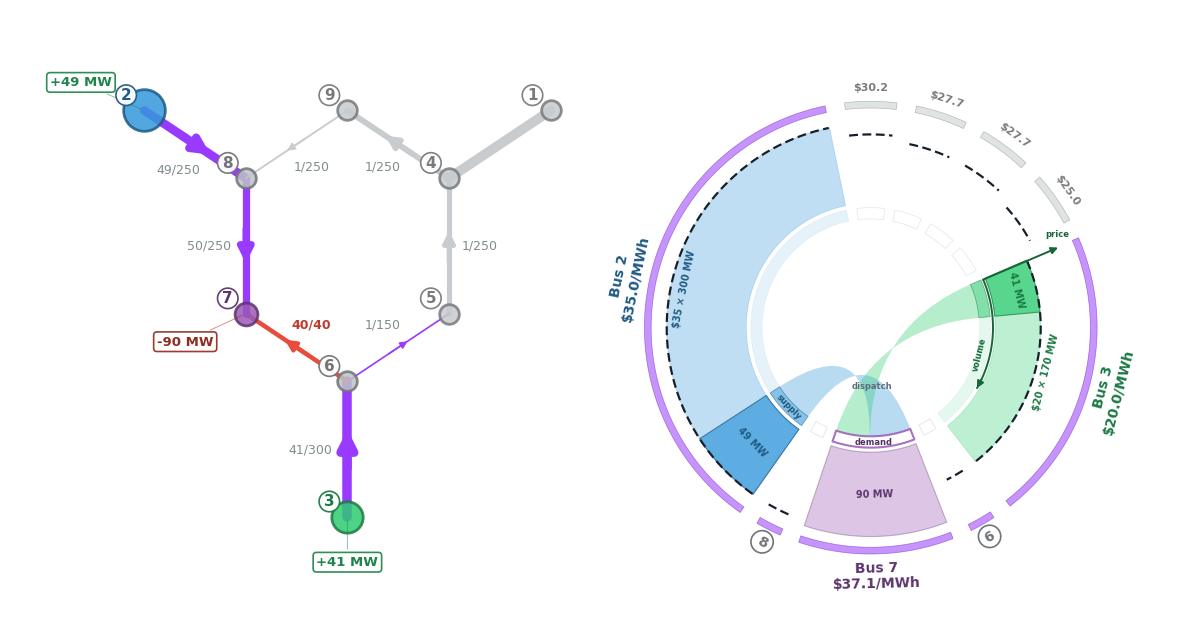

In [8]:
A1 = engine_a(LOAD_7)
rA1 = clear(A1)
market_block(A1, rA1)
seam_views.own_view(net, pt, fp, "Market A", A1, rA1)
plt.show()

In [9]:
MU = abs(rA1.line_dual[STUDY_LINE])
# The interior pair's offers c_i, read from the EDIT cell's fleet.
C_HI = float(GEN_FLEET["gen_0"]["cost"])
C_LO = float(GEN_FLEET["gen_1"]["cost"])
F_A1 = rA1.flow_own[STUDY_LINE]
SETTLE_A1 = settlement_by_bus(rA1, MARKETS["Market A"], A1.loads)
RENT_A1 = capacity_value_by_line(rA1, pt, A1.activated_lines)
print(SETTLE_A1.to_string())
print()
print(RENT_A1.to_string())
print()
# (6) both ways: the settlement total (load pays less generation is paid) and the line
# total, each rounded to $0.1/h by the library, and |mu| x |F^A| unrounded.
R_SETTLE = (SETTLE_A1.loc["SUBTOTAL", "paid by load ($/h)"]
            - SETTLE_A1.loc["SUBTOTAL", "paid to gen ($/h)"])
R_LINES = float(RENT_A1.loc["TOTAL", "rent |mu| x flow ($/h)"])
R_A1 = MU * abs(F_A1)
print(f"(6): settlement total ${R_SETTLE:,.1f}/h, line total ${R_LINES:,.1f}/h; "
      f"|mu| x |F^A| = {MU:.4f} x {abs(F_A1):.3f} = ${R_A1:,.3f}/h")

# The dual is the interior pair's offer gap over their shift-factor gap on line 6-7.
_hi, _lo = GEN_FLEET["gen_0"], GEN_FLEET["gen_1"]
_sf = {u["bus"]: pt.ptdf[pt.line_idx[STUDY_LINE], pt.bus_idx[u["bus"]]] for u in (_hi, _lo)}
MU_PAIR = (C_HI - C_LO) / (_sf[_lo["bus"]] - _sf[_hi["bus"]])
print(f"{STUDY_LINE} ({line_ends(STUDY_LINE)}): own flow {F_A1:+.3f} MW, |mu| {MU:.4f} $/MWh, "
      f"({C_HI:g} - {C_LO:g}) / (SF[{_lo['bus']}] - SF[{_hi['bus']}]) = "
      f"{MU_PAIR:.4f} $/MWh, R = ${R_A1:,.3f}/h")

         LMP ($/MWh)  gen (MW)  paid to gen ($/h)  load (MW)  paid by load ($/h)
bus                                                                             
2               35.0      49.1             1717.4        0.0                 0.0
8               35.0       0.0                0.0        0.0                 0.0
7              37.13       0.0                0.0       89.9              3338.7
6               20.0       0.0                0.0        0.0                 0.0
3               20.0      40.9              817.2        0.0                 0.0
SUBTOTAL                  89.9             2534.6       89.9              3338.7

       from to flow (MW) rating (MW) binding |mu| ($/MWh = value of +1 MW)  rent |mu| x flow ($/h)
line                                                                                              
line_2    5  6      -0.9       150.0   False                           0.0                     0.0
line_3    3  6      40.9       300.0   False                           0.0                     0.0
line_4    6  7      40.0        40.0    True                          20.1                   804.1
line_5    7  8     -49.9       250.0   False                           0.0                     0.0
line_6    8  2     -49.1       250.0   False                           0.0                     0.0
TOTAL                                                                                        804.1

(6): settlement total $804.1/h, line total $804.1/h; |mu| x |F^A| = 20.1024 x 40.000 = $804.094/h

line_4 (6-7): own flow +40.000 MW, |mu| 20.1024 $/MWh, (35 - 20) / (SF[3] - SF[2]) = 20.1024 $/MWh, R = $804.094/h

### Slide 7: the bus-7 price as a production-cost change

One more MW of load at bus 7 is served by raising the bus-2 unit and lowering the bus-3 unit, in the proportions that hold line 6-7 at its rating. This is the first walk under (5). `seam_views.price_walk` solves the pair and `seam_views.walk_text` prints it. The cost of the pair is Market A's bus-7 LMP.

In [10]:
WALK_7, BIND_7 = seam_views.price_walk(pt, A1, rA1, "7")
print(seam_views.walk_text(WALK_7, "7", "Market A", rA1.lmp["7"], True, binding=BIND_7))

Market A -- bus 7, inside its footprint: the cost of one more MW of load

  gen_1 at bus 3: -0.1417 MW  x  $20.00/MWh           =  -$     2.83/h
  gen_0 at bus 2: +1.1417 MW  x  $35.00/MWh           =   $    39.96/h
  ------------------------------------------------------------------
  change in production cost                           =   $    37.13/h
  Market A's price at bus 7                           =   $    37.13/MWh   (binding: line_4)

### Slide 8: the line 6-7 shadow price as a production-cost change

One MW off line 6-7 is found by raising the bus-2 unit and lowering the bus-3 unit by the same amount, $1/(SF_{3,m}-SF_{2,m})$ MW with $m$ line 6-7. This is the second walk under (5), and the notebook-local `line_walk` solves it. Its cost is $\lvert\mu^A_m\rvert$.

In [11]:
WALK_L = line_walk(A1, rA1, STUDY_LINE)
print(line_walk_text(WALK_L, STUDY_LINE, "Market A", rA1.line_dual[STUDY_LINE]))
SF_67 = {b: pt.ptdf[pt.line_idx[STUDY_LINE], pt.bus_idx[b]] for b in pt.buses}
print(f"\nshift factors on {STUDY_LINE}: "
      + ", ".join(f"bus {b} {v:+.5f}" for b, v in SF_67.items()))
print(f"1 / (SF[3] - SF[2]) = 1 / {SF_67['3'] - SF_67['2']:.5f} = "
      f"{1.0 / (SF_67['3'] - SF_67['2']):.5f} MW")

Market A -- line 6-7 (line_4): the cost of one MW off the line

  gen_1 at bus 3: -1.3402 MW  x  $20.00/MWh           =  $   -26.80/h
  gen_0 at bus 2: +1.3402 MW  x  $35.00/MWh           =  $   +46.91/h
  ------------------------------------------------------------------
  change in production cost                           =  $   +20.10/h
  Market A |mu| on line_4                             =  $    20.10/MWh


shift factors on line_4: bus 1 +0.00000, bus 2 -0.36134, bus 3 +0.38484, bus 4 +0.00000, bus 5 +0.13514, bus 6 +0.38484, bus 7 -0.46710, bus 8 -0.36134, bus 9 -0.12485

1 / (SF[3] - SF[2]) = 1 / 0.74618 = 1.34016 MW

### Slide 9: Market B clears

Market B clears (1) at the realized bus-9 load. Its one unit, at bus 1, serves both its loads, no line in $\mathcal M^B_{\mathrm{act}}$ binds, and every LMP is the unit's \$50/MWh offer. By (2), Market B's dispatch places 9.4 MW on line 6-7. Line 6-7 is not in $\mathcal M^B_{\mathrm{mon}}$, so Market B neither monitors nor prices that flow.

Market B: production cost $13,153.49/h, energy price $50.000/MWh

  dispatch: gen_slack_0 at bus 1 263.07 MW

  line_4 (6-7): own flow +9.446 MW, input +0.000 MW, rating 40 MW, |mu| 0.0000 $/MWh, not in the activated set

  LMP ($/MWh): bus 1 50.000, bus 2 50.000, bus 3 50.000, bus 4 50.000, bus 5 50.000, bus 6 50.000, bus 7 50.000, bus 8 50.000, bus 9 50.000

line 6-7 in Market B's monitored set: False

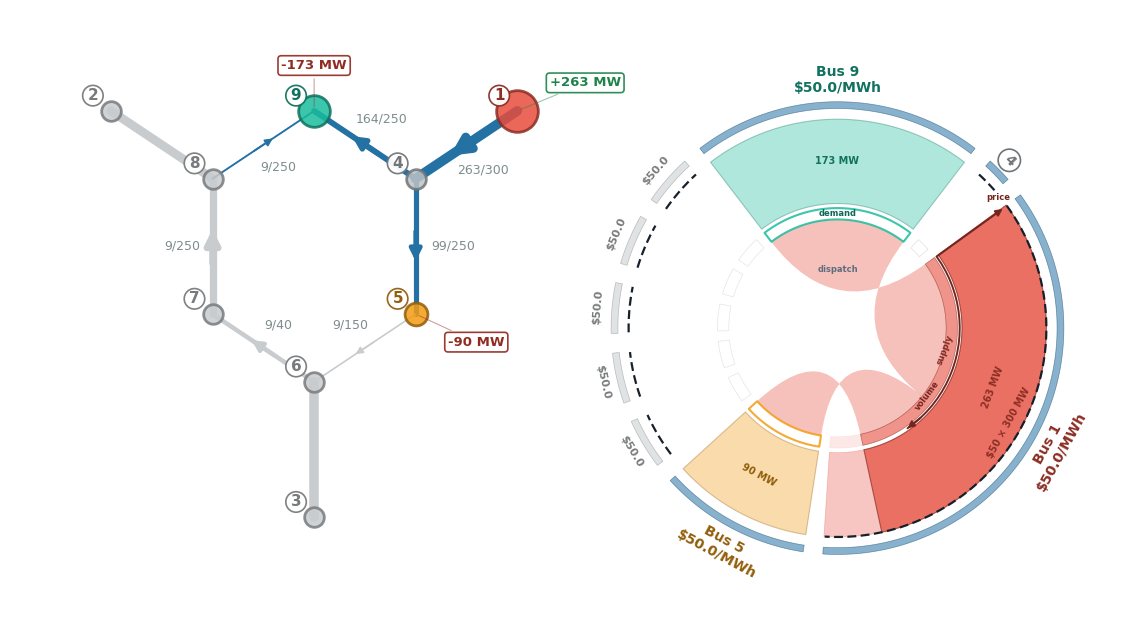

In [12]:
B = engine_b(LOAD_9)
rB = clear(B)
FB = rB.flow_own[STUDY_LINE]
market_block(B, rB)
print(f"line 6-7 in Market B's monitored set: {STUDY_LINE in MONITORED_LINES['Market B']}")
seam_views.own_view(net, pt, fp, "Market B", B, rB)
plt.show()

### Slide 10: the superposed flow

By (3), line 6-7 carries Market A's 40.0 MW plus Market B's 9.4 MW, 49.4 MW against its 40 MW rating. Each market's clear is feasible on its own activated set, and the superposition overloads line 6-7, as (4) allows. `seam_views.combined_views` draws the superposition twice, first as the combined letter and then as the standalone network with each bus's combined net injection. Slide 10's right panel is the second figure.

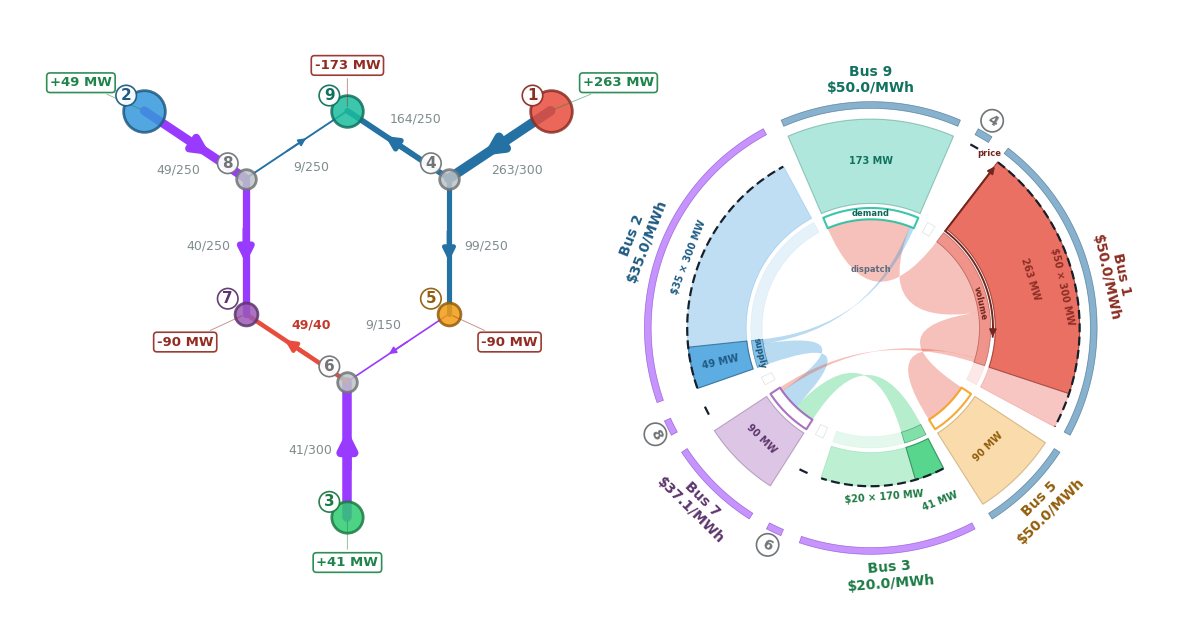

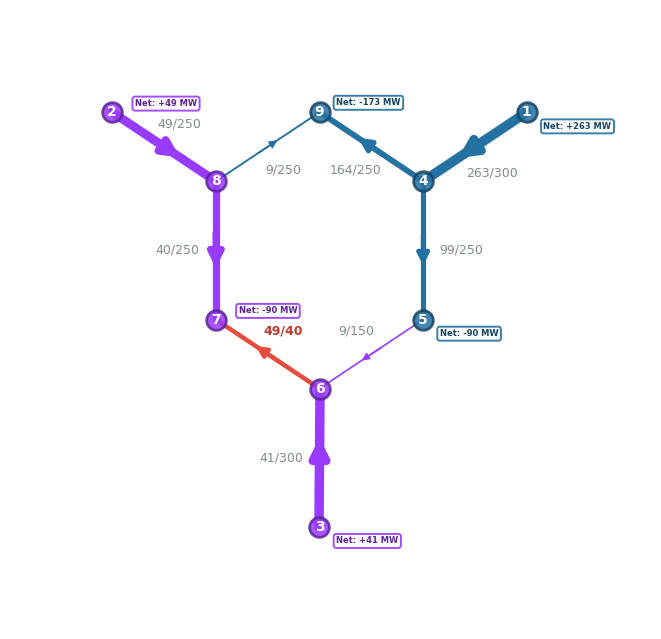

       from to  F[Market A]  F[Market B]    F^s  rating  loading_%  overload
line                                                                        
line_0    1  4          0.0        263.1  263.1   300.0       88.0     False
line_1    4  5         -0.9         99.4   98.6   250.0       39.0     False
line_2    5  6         -0.9          9.4    8.6   150.0        6.0     False
line_3    3  6         40.9         -0.0   40.9   300.0       14.0     False
line_4    6  7         40.0          9.4   49.4    40.0      124.0      True
line_5    7  8        -49.9          9.4  -40.5   250.0       16.0     False
line_6    8  2        -49.1          0.0  -49.1   250.0       20.0     False
line_7    8  9         -0.9          9.4    8.6   250.0        3.0     False
line_8    9  4         -0.9       -163.6 -164.5   250.0       66.0     False

In [13]:
PF1 = seam_views.combined_views(net, pt, fp, [(A1, rA1), (B, rB)], "")
plt.show()
print(PF1.rename(columns={"F_phys": "F^s"}).to_string())

### Slide 11: Market A redispatches to Market B's realized flow

Market A clears (1) again with $\widehat F^{B}$ set to Market B's realized flow on Market A's activated lines. This redispatch is Market A's accommodation of Market B's flow. The bus-2 unit rises and the bus-3 unit falls by 12.66 MW each, and line 6-7 carries Market A's 30.6 MW plus Market B's 9.4 MW, 40.0 MW.

The first figure is the combined letter, with line 6-7 drawn red as Market A's binding line. The second is the standalone network, which slide 11 does not show.

Market A: production cost $2,724.54/h, energy price $27.736/MWh

  dispatch: gen_1 at bus 3 28.20 MW, gen_0 at bus 2 61.73 MW

  line_4 (6-7): own flow +30.554 MW, input +9.446 MW, rating 40 MW, |mu| 20.1024 $/MWh

  LMP ($/MWh): bus 1 27.736, bus 2 35.000, bus 3 20.000, bus 4 27.736, bus 5 25.020, bus 6 20.000, bus 7 37.126, bus 8 35.000, bus 9 30.246

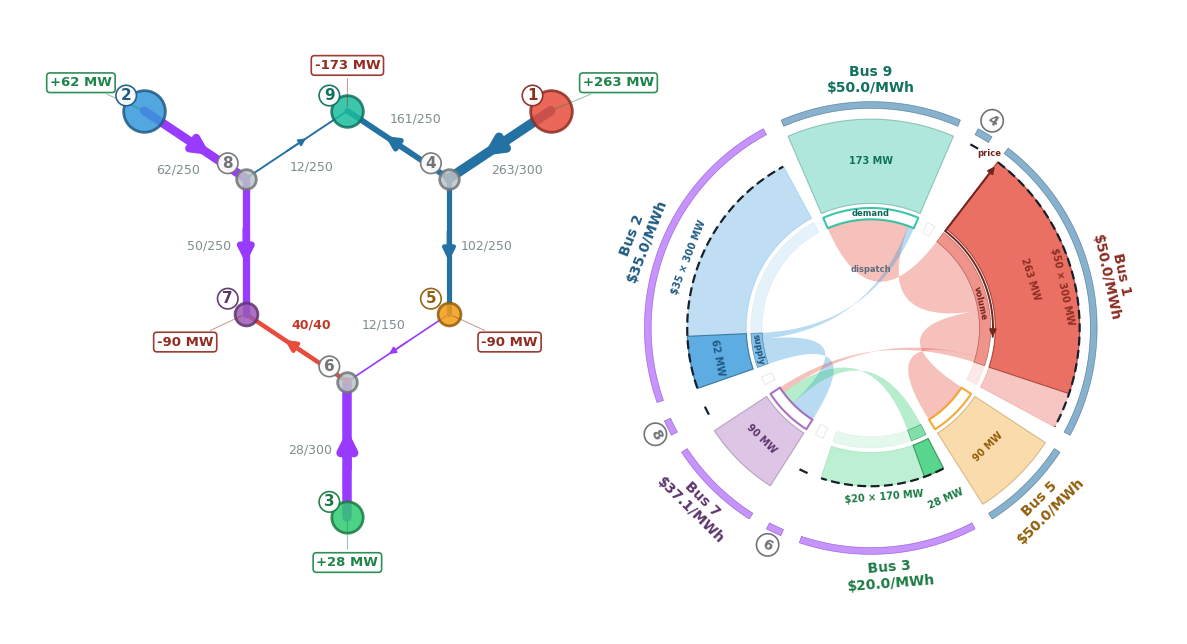

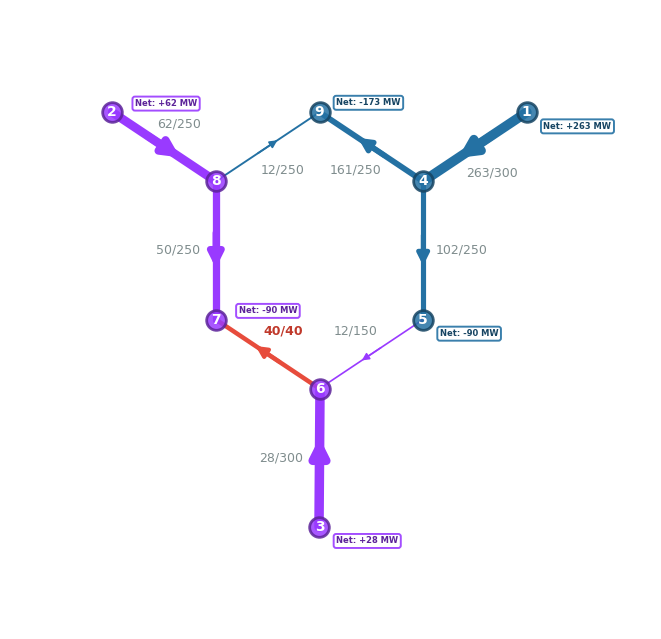

In [14]:
OFF_B = offsets_on(rB, A1)
A1r = engine_a(LOAD_7)
rA1r = clear(A1r, OFF_B)
market_block(A1r, rA1r, OFF_B)
PF1R = seam_views.combined_views(net, pt, fp, [(A1r, rA1r), (B, rB)], "",
                                 binding=[STUDY_LINE])
plt.show()

In [15]:
ACC_TABLE = cost_table(A1, [("no input", rA1, None),
                            ("Market B's realized flow", rA1r, OFF_B)], rB)
print(ledger_text(ACC_TABLE, f"Market A's production cost before and after accommodation, "
                             f"flows on line {line_ends(STUDY_LINE)}"))
print()
ACC_LEDGER = accommodation_ledger(A1, rA1, rA1r, OFF_B[STUDY_LINE])
print(ledger_text(ACC_LEDGER, "The cost of accommodating Market B's realized flow"))

Market A's production cost before and after accommodation, flows on line 6-7
                         bus 2 unit (MW) bus 3 unit (MW) production cost ($/h) input (MW) own flow (MW) superposed (MW) rating (MW) |mu| ($/MWh)
no input                          49.070          40.860              2,534.65      0.000        40.000          49.446      40.000      20.1024
Market B's realized flow          61.729          28.201              2,724.54      9.446        30.554          40.000      40.000      20.1024

The cost of accommodating Market B's realized flow
                                   quantity (MW) price ($/MWh) cost ($/h)
gen_0 at bus 2: redispatch x offer        12.659       35.0000     443.08
gen_1 at bus 3: redispatch x offer       -12.659       20.0000    -253.19
change in production cost, the sum                                 189.89
(7): input x |mu|                          9.446       20.1024     189.89
residual, the sum less (7)                                           0.00

Accommodating Market B's realized flow on line 6-7, $F^B_m=9.446$ MW, brings the superposed flow from 49.45 MW to the 40 MW rating and raises Market A's production cost from \$2,534.65/h to \$2,724.54/h. The rise of \$189.89/h is the absolute dual, $\lvert\mu^A_m\rvert=\$20.10$/MWh, times that flow, as (7) states, and the residual is zero.

## Example 2: over-forecast of the neighbor's flow contribution (slides 12 to 18)

Each market forecasts the other's use of the network. Market A clears (1) with $\widehat F^{B}$ set to the flow of its forecast of Market B's book on its activated lines. Market B has no binding line, and line 6-7 is not in its monitored set $\mathcal M^B_{\mathrm{mon}}$. Market B delivers less flow on line 6-7 than Market A's forecast held for it, so the line carries less than its rating.

**Phantom congestion** is congestion that Market A prices and relieves on line 6-7 and that the superposed flow does not produce. Market A's production cost on the forecast exceeds its production cost on Market B's realized flow. By (7), the excess is the absolute dual of line 6-7, $\lvert\mu^A_m\rvert$, times the over-forecast, $\widehat F^B_m-F^B_m$. Slide 12 states that Market A bears the cost of phantom congestion.

The joint CAISO and SPP report describes how CAISO forms such a forecast for an area outside its market: "Using submitted generation schedules combined with historical observations and established heuristics, CAISO develops a set of modeled injections to balance forecast demand in non-market Balancing Authority Areas" (`caiso_spp_jointreport2026`, p. 25).

### Slide 13: Market A's input, its forecast of Market B

Market A forecasts Market B's book by clearing Market B's engine at Market A's forecast of the bus-9 load, 189.86 MW against the realized 173.07 MW. The forecast book places 11.5 MW on line 6-7, against the 9.4 MW Market B delivers. `seam_views.forecast_view` draws the forecast book alone, in gray. Market A's side is drawn as configured, at nameplate and with the configured 100 MW load at bus 7, although Market A clears at the realized 89.93 MW.

Market B: production cost $13,993.21/h, energy price $50.000/MWh

  dispatch: gen_slack_0 at bus 1 279.86 MW

  line_4 (6-7): own flow +11.543 MW, input +0.000 MW, rating 40 MW, |mu| 0.0000 $/MWh, not in the activated set

  LMP ($/MWh): bus 1 50.000, bus 2 50.000, bus 3 50.000, bus 4 50.000, bus 5 50.000, bus 6 50.000, bus 7 50.000, bus 8 50.000, bus 9 50.000

forecast flow on line 6-7 +11.54296 MW; realized +9.44615 MW

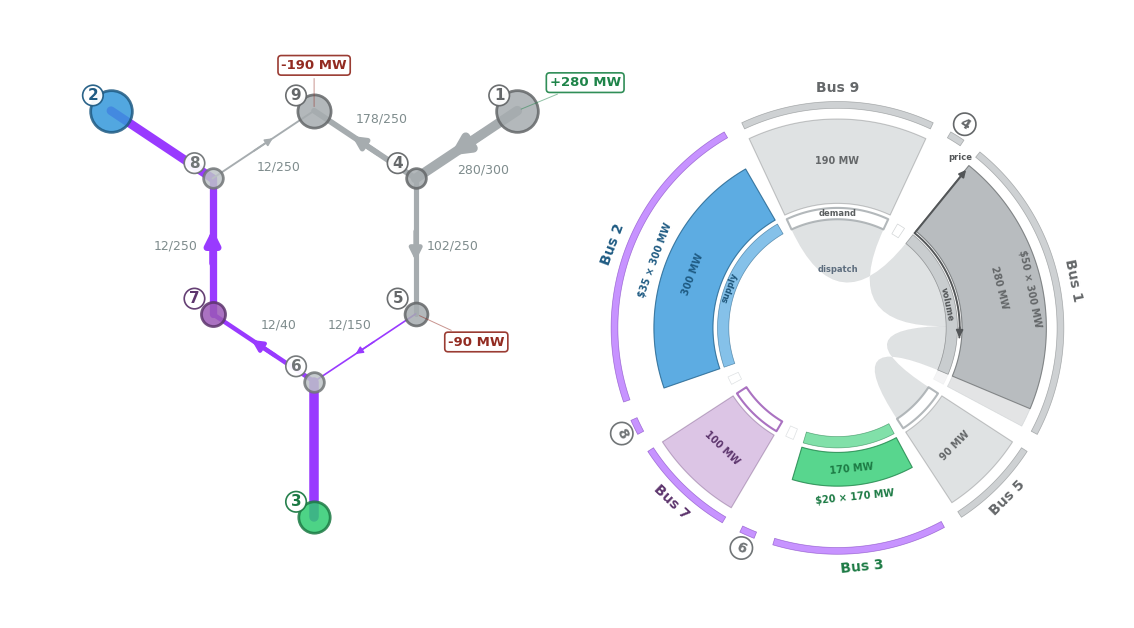

In [16]:
Bf = engine_b(LOAD_9_FORECAST_BY_A)
rBf = clear(Bf)
market_block(Bf, rBf)
FB_HAT = rBf.flow_own[STUDY_LINE]
print(f"forecast flow on line 6-7 {FB_HAT:+.5f} MW; realized {FB:+.5f} MW")
seam_views.forecast_view(net, pt, fp, Bf, rBf, "")
plt.show()

### Slide 14: Market A clears against the forecast

Market A clears (1) with $\widehat F^{B}$ set to the forecast book's flow on its activated lines. Line 6-7 holds Market A's own 28.5 MW plus the forecast 11.5 MW at 40 MW. Against the clear with $\widehat F^{B}=0$, the bus-2 unit rises and the bus-3 unit falls by 15.47 MW each, and Market A's production cost rises by \$232.04/h to \$2,766.69/h. By (7), the rise is the forecast 11.543 MW times $\lvert\mu^A_m\rvert$. The network panel draws Market A's own flow plus the forecast flow, and the ring draws the forecast book in gray.

Market A: production cost $2,766.69/h, energy price $27.736/MWh

  dispatch: gen_1 at bus 3 25.39 MW, gen_0 at bus 2 64.54 MW

  line_4 (6-7): own flow +28.457 MW, input +11.543 MW, rating 40 MW, |mu| 20.1024 $/MWh

  LMP ($/MWh): bus 1 27.736, bus 2 35.000, bus 3 20.000, bus 4 27.736, bus 5 25.020, bus 6 20.000, bus 7 37.126, bus 8 35.000, bus 9 30.246

The cost of accommodating the forecast of Market B's flow
                                   quantity (MW) price ($/MWh) cost ($/h)
gen_0 at bus 2: redispatch x offer        15.469       35.0000     541.43
gen_1 at bus 3: redispatch x offer       -15.469       20.0000    -309.39
change in production cost, the sum                                 232.04
(7): input x |mu|                         11.543       20.1024     232.04
residual, the sum less (7)                                           0.00

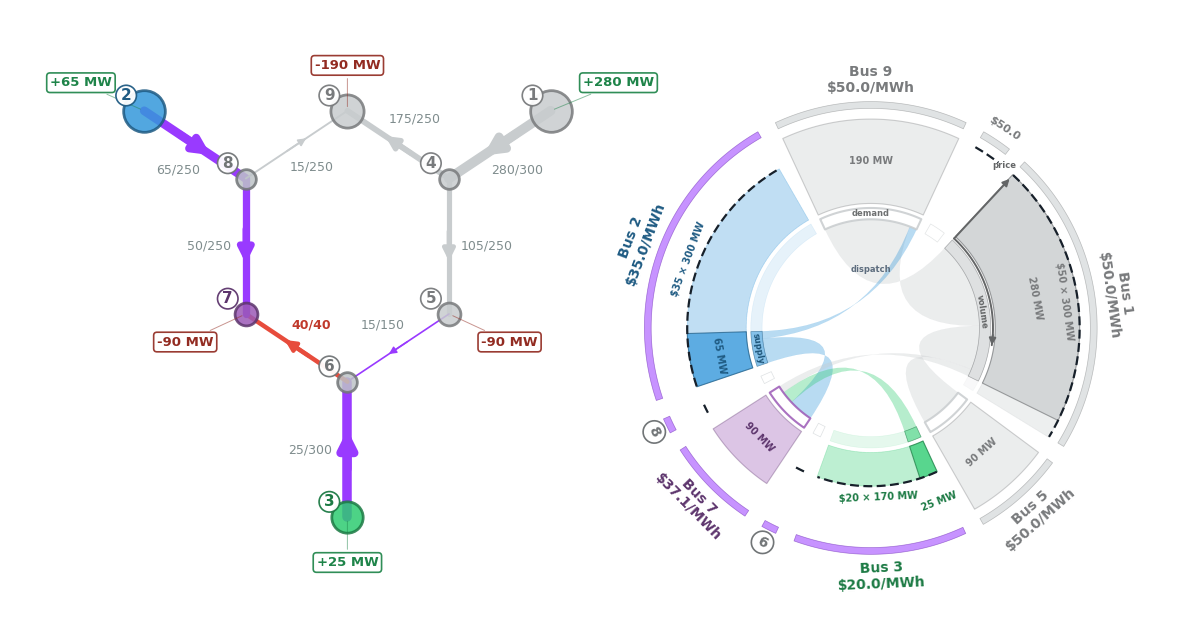

In [17]:
OFF_BF = offsets_on(rBf, engine_a(LOAD_7))
A2 = engine_a(LOAD_7)
rA2 = clear(A2, OFF_BF)
market_block(A2, rA2, OFF_BF)
print()
print(ledger_text(accommodation_ledger(A2, rA1, rA2, OFF_BF[STUDY_LINE]),
                  "The cost of accommodating the forecast of Market B's flow"))
seam_views.own_view(net, pt, fp, "Market A", A2, rA2, proxy=(Bf, rBf))
plt.show()

### Slide 15: Market B clears, with its forecast of Market A

Market B forecasts Market A's book by clearing Market A's engine at Market B's forecast of the bus-7 load, 83.06 MW against the realized 89.93 MW. The first figure is that forecast book alone, the lower Inputs picture of slide 18. Market B then clears (1) with $\widehat F^{A}$ set to the forecast book's flow on its activated lines. No line in $\mathcal M^B_{\mathrm{act}}$ binds with or without that input, so Market B's dispatch and prices are those of slide 9.

The second figure is slide 15, Market B's clear with its forecast of Market A in gray. Its network panel carries the studied superposition, 49.4 MW on line 6-7 against the 40 MW rating. Market B calculates that flow, but line 6-7 is not in $\mathcal M^B_{\mathrm{mon}}$, so Market B neither monitors nor enforces it.

Market A: production cost $2,279.41/h, energy price $27.736/MWh

  dispatch: gen_1 at bus 3 41.83 MW, gen_0 at bus 2 41.22 MW

  line_4 (6-7): own flow +40.000 MW, input +0.000 MW, rating 40 MW, |mu| 20.1024 $/MWh

  LMP ($/MWh): bus 1 27.736, bus 2 35.000, bus 3 20.000, bus 4 27.736, bus 5 25.020, bus 6 20.000, bus 7 37.126, bus 8 35.000, bus 9 30.246

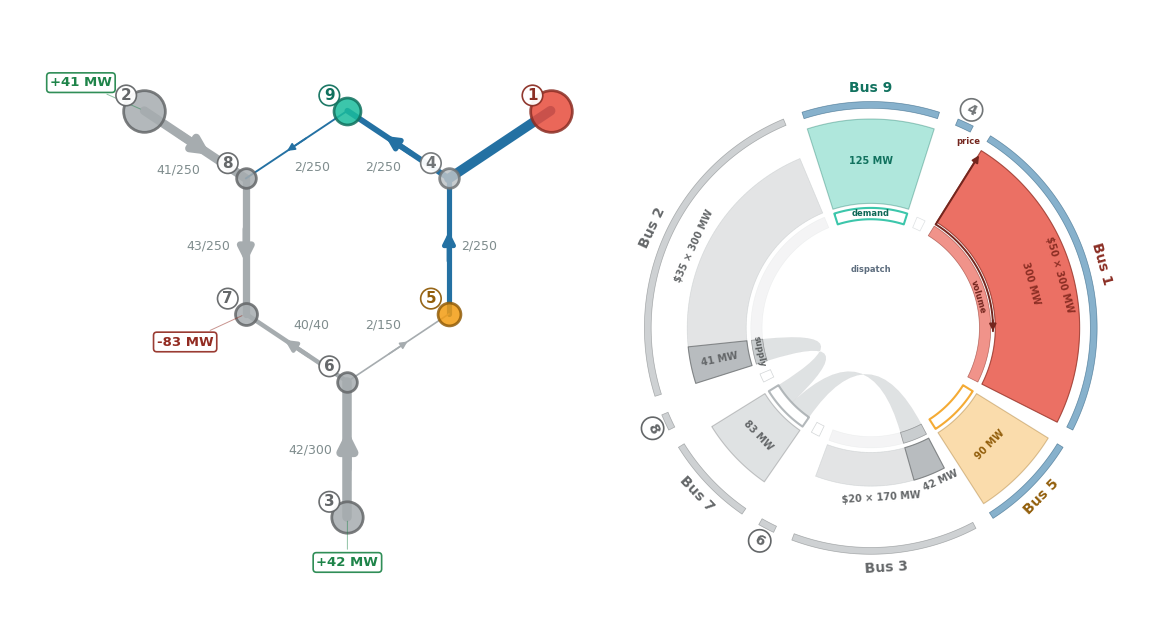

Market B: production cost $13,153.49/h, energy price $50.000/MWh

  dispatch: gen_slack_0 at bus 1 263.07 MW

  line_4 (6-7): own flow +9.446 MW, input +0.000 MW, rating 40 MW, |mu| 0.0000 $/MWh, not in the activated set

  LMP ($/MWh): bus 1 50.000, bus 2 50.000, bus 3 50.000, bus 4 50.000, bus 5 50.000, bus 6 50.000, bus 7 50.000, bus 8 50.000, bus 9 50.000

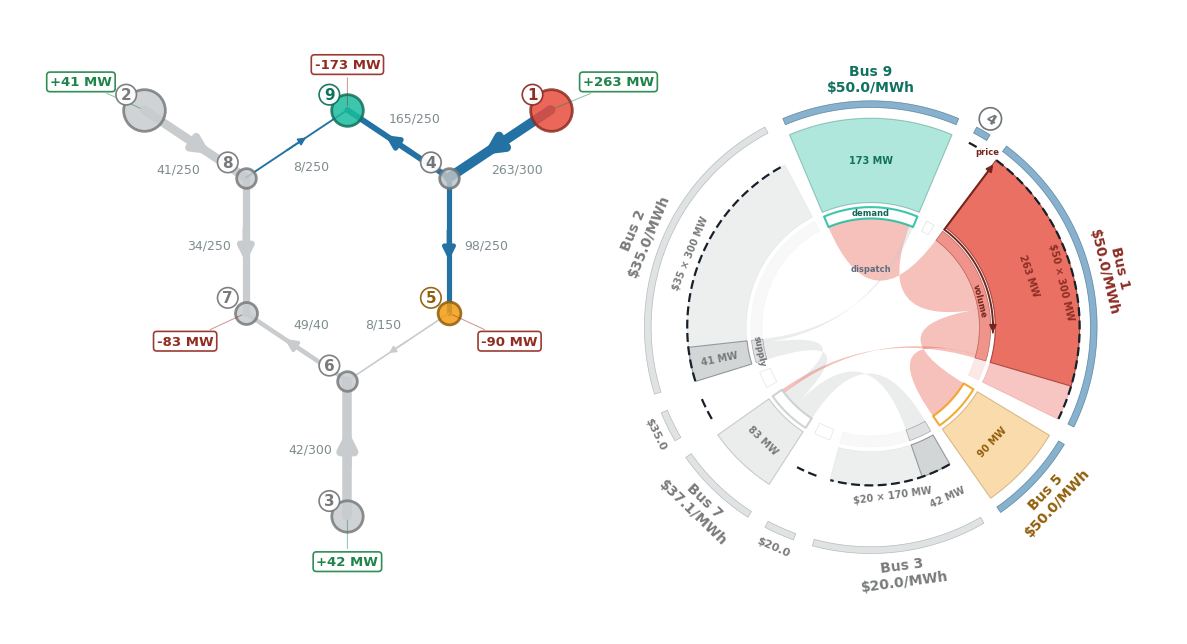

In [18]:
Ap = engine_a(LOAD_7_FORECAST_BY_B)
rAp = clear(Ap)
market_block(Ap, rAp)
seam_views.forecast_view(net, pt, fp, Ap, rAp, "")
plt.show()
B2 = engine_b(LOAD_9)
OFF_AP = offsets_on(rAp, B2)
rB2 = clear(B2, OFF_AP)
market_block(B2, rB2, OFF_AP)
seam_views.own_view(net, pt, fp, "Market B", B2, rB2, proxy=(Ap, rAp))
plt.show()

### Slide 16: the superposed flow

Line 6-7 carries Market A's 28.5 MW plus Market B's 9.4 MW, 37.9 MW against its 40 MW rating. Market B delivers 2.1 MW less on line 6-7 than Market A's forecast held for it. Slide 16's right panel is the second figure, the standalone network. `combined_views` rounds the superposed flow to 0.1 MW before its line label rounds to a whole megawatt, half to even, so line 8-2's 64.54 MW is labelled 64.

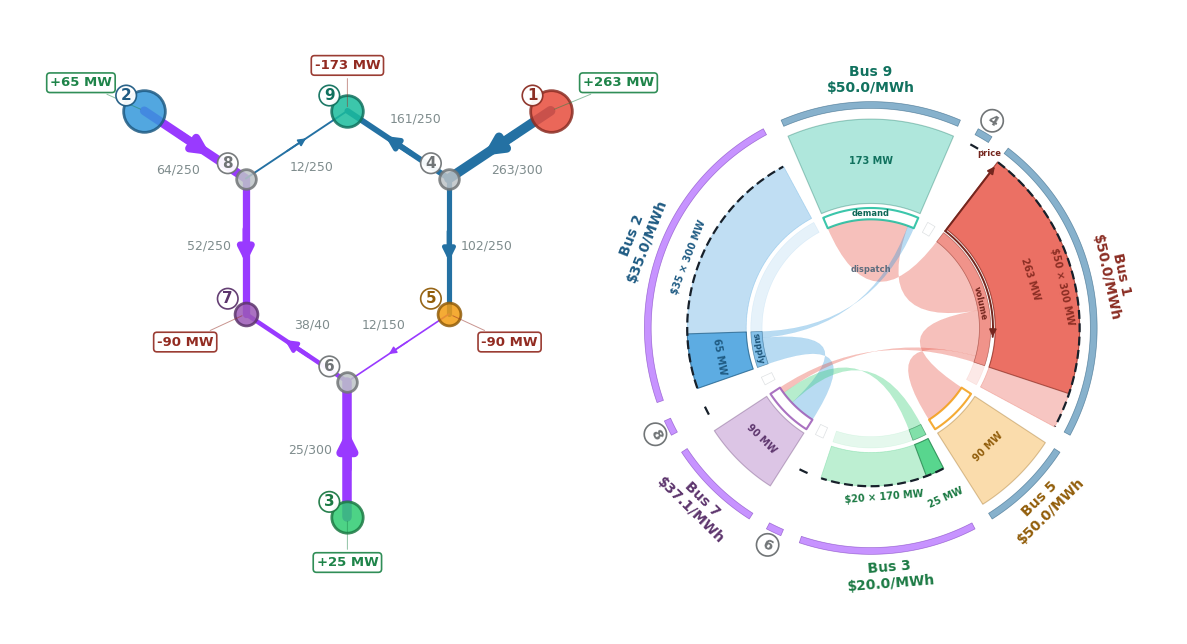

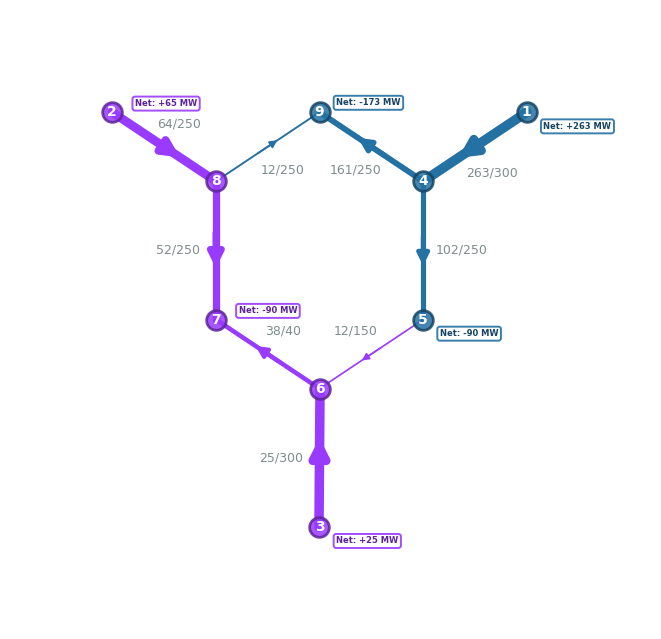

       from to  F[Market A]  F[Market B]    F^s  rating  loading_%  overload
line                                                                        
line_0    1  4          0.0        263.1  263.1   300.0       88.0     False
line_1    4  5          3.1         99.4  102.5   250.0       41.0     False
line_2    5  6          3.1          9.4   12.5   150.0        8.0     False
line_3    3  6         25.4         -0.0   25.4   300.0        8.0     False
line_4    6  7         28.5          9.4   37.9    40.0       95.0     False
line_5    7  8        -61.5          9.4  -52.0   250.0       21.0     False
line_6    8  2        -64.5          0.0  -64.5   250.0       26.0     False
line_7    8  9          3.1          9.4   12.5   250.0        5.0     False
line_8    9  4          3.1       -163.6 -160.6   250.0       64.0     False

In [19]:
PF2 = seam_views.combined_views(net, pt, fp, [(A2, rA2), (B2, rB2)], "")
plt.show()
print(PF2.rename(columns={"F_phys": "F^s"}).to_string())

### Slide 17: the cost of phantom congestion

Each of Market A's three clears is superposed on Market B's clear of slide 15. The ledger applies (7) to Market A's clear on Market B's realized flow, the redispatch of slide 11, and to its clear on the forecast, and takes their difference. Slide 17's picture is the combined letter, the first figure of the slide 16 cell.

In [20]:
PHANTOM_TABLE = cost_table(A1, [("no input", rA1, None),
                                ("Market B's realized flow", rA1r, OFF_B),
                                ("forecast of Market B", rA2, OFF_BF)], rB2)
print(ledger_text(PHANTOM_TABLE, "Market A's production cost on no input, on Market B's "
                                 "realized flow and on the forecast, flows on line "
                                 f"{line_ends(STUDY_LINE)}"))
print()
PHANTOM_LEDGER = phantom_ledger(rA1, rA1r, rA2, rB2, OFF_BF[STUDY_LINE])
print(ledger_text(PHANTOM_LEDGER, "The cost of phantom congestion"))

Market A's production cost on no input, on Market B's realized flow and on the forecast, flows on line 6-7
                         bus 2 unit (MW) bus 3 unit (MW) production cost ($/h) input (MW) own flow (MW) superposed (MW) rating (MW) |mu| ($/MWh)
no input                          49.070          40.860              2,534.65      0.000        40.000          49.446      40.000      20.1024
Market B's realized flow          61.729          28.201              2,724.54      9.446        30.554          40.000      40.000      20.1024
forecast of Market B              64.539          25.391              2,766.69     11.543        28.457          37.903      40.000      20.1024

The cost of phantom congestion
                                                          line 6-7 (MW) |mu| ($/MWh) from the clears ($/h) (7): |mu| x MW ($/h) residual ($/h)
accommodating Market B's realized flow: C^A(F^B) - C^A(0)         9.446      20.1024                189.89               189.89           0.00
accommodating the forecast: C^A(forecast) - C^A(0)               11.543      20.1024                232.04               232.04           0.00
phantom congestion: C^A(forecast) - C^A(F^B)                      2.097      20.1024                 42.15                42.15           0.00
superposed flow, forecast clear with Market B's clear            37.903                                                                       
rating                                                           40.000                                                                       
unused capacity, rating less superposed flow                      2.097                                        

Market A's clear on the forecast costs \$2,766.69/h, \$42.15/h more than its clear on Market B's realized flow. That \$42.15/h is the cost of phantom congestion, the absolute dual times the 2.10 MW of line 6-7's rating that the superposed flow leaves unused, and the residual of (7) is zero. Slide 17 states the \$42 as "increased production cost because of inefficient use of system".

### Slide 18: the parallel process

Slide 18 shows Example 2 in three stages: inputs, optimization and reconciliation. The inputs are each market's forecast of the other, drawn in the slide 13 cell and as the first figure of the slide 15 cell. The optimization is each market's clear on its forecast, drawn in the slide 14 cell and as the second figure of the slide 15 cell. The reconciliation is the superposed flow of slide 16, then Market A's redispatch to Market B's realized flow. That redispatch is slide 11's clear. Its inputs, Market A's realized load and Market B's realized flow, do not depend on either forecast, so it is not drawn again. The slide 17 table carries Market A's optimization and reconciliation clears, with their production costs and their flows on line 6-7.

## Slide 19

Slide 19 lists three considerations: data sharing, modeling, and the methodology for managing jointly impacted constraints. It prints no number.

## Sandbox

The sandbox reruns the notebook's chain on the values in the EDIT cell: Market B's clear, Market B's clear at Market A's forecast, and Market A's three clears, with no input, with Market B's realized flow and with the forecast. It prints the cost of accommodation and the cost of phantom congestion, each with its residual of (7) and the superposed flow on the study line against its rating, and returns one row per clear.

`run_chain` reads the footprints, the activated lines, the fleet, the bus-5 load, the shed price, the study line and three drawn loads: `LOAD_7`, `LOAD_9` and `LOAD_9_FORECAST_BY_A`. No clear in the chain uses `LOAD_7_FORECAST_BY_B` or `MONITORED_LINES`. The ratings and the reference bus reach it through the shift factors, which the case cell after the EDIT cell builds, so a change to either needs that cell rerun. `run_chain` also takes the bus-7 load, the bus-9 load and Market A's forecast of the bus-9 load as arguments, so one call tests another forecast without editing the EDIT cell.

The configurable standalone notebook `101_sandbox.ipynb` clears the 9-bus case from one configuration cell, as one market or as two independent markets on the same network.

In [21]:
run_chain()

line_4 (6-7) rating 40 MW; Market B's realized flow on it +9.446 MW, the forecast +11.543 MW

cost of accommodation: +189.89 $/h; (7) |mu| x F^B +189.89 $/h; residual 0.00 $/h; superposed flow 49.446 MW with no input and 40.000 MW after, against 40 MW

cost of phantom congestion: +42.15 $/h; (7) |mu| x (forecast - F^B) +42.15 $/h; residual 0.00 $/h; superposed flow 37.903 MW on the forecast against 40 MW, unused 2.097 MW

,production cost ($/h),own flow line_4 (MW),input line_4 (MW),superposed line_4 (MW),|mu| ($/MWh)
clear,,,,,
Market B,13153.493,9.446,0.000,NaN,0.000
"Market A, no input (Example 1)",2534.647,40.000,0.000,49.446,20.102
"Market A, input = B's realized flow",2724.537,30.554,9.446,40.000,20.102
"Market A, input = forecast of B (Example 2)",2766.688,28.457,11.543,37.903,20.102
